# Лабораторна робота №2. Фігури Хладні

In [2]:
import time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import matplotlib.pyplot as plt

pi = np.pi

### Постановка задачі

$$
U_{tt} = c^2 (U_{xx} + U_{yy}), \quad (x, y) \in [0, L_x] \times [0, L_y]
$$

$$
U(x, y, 0) = 0, \quad U_t(x, y, 0) = 0, \quad U(x_s, y_s, t) = A \sin(\omega t + \varphi)
$$

### Лапласіан

In [3]:
def d2(n, h):
    D = sp.diags([1, -2, 1], [-1, 0, 1], shape=(n, n), format="lil", dtype=float)
    D[0, 1] = 2          
    D[n - 1, n - 2] = 2
    return D / h**2


def laplacian(nx, ny, h):
    return sp.kron(d2(nx, h), sp.eye(ny)) + sp.kron(sp.eye(nx), d2(ny, h))


print(d2(5, 1).toarray())

[[-2.  2.  0.  0.  0.]
 [ 1. -2.  1.  0.  0.]
 [ 0.  1. -2.  1.  0.]
 [ 0.  0.  1. -2.  1.]
 [ 0.  0.  0.  2. -2.]]


### Різницеві схеми

In [4]:
# ваги лапласіана на шарах n+1, n, n-1
schemes = {
    "explicit": (0, 1, 0),
    "implicit": (1, 0, 0),
    "cn":       (0.5, 0, 0.5),
}

### Розв'язання

In [5]:
def solve(nx=101, ny=101, h=0.01, dt=0.01, steps=500, w=10 * pi, A=1e-4,
          sources=((0.5, 0.5, 0),), fixed="", scheme="cn", gamma=0):
    N = nx * ny
    w1, w0, wm1 = schemes[scheme]
    g = gamma / (2 * dt)
    L = laplacian(nx, ny, h)

    # вузли з відомим значенням
    mask = np.zeros((nx, ny), dtype=bool)
    if "l" in fixed: mask[0, :] = True
    if "r" in fixed: mask[-1, :] = True
    if "b" in fixed: mask[:, 0] = True
    if "t" in fixed: mask[:, -1] = True
    src = []
    for xs, ys, ph in sources:
        i, j = round(xs / h), round(ys / h)
        mask[i, j] = True
        src.append((i * ny + j, ph))
    mask = mask.ravel()

    M = (1 / dt**2 + g) * sp.eye(N) - w1 * L
    M = sp.diags(1.0 - mask) @ M + sp.diags(mask * 1.0)
    lu = splu(M.tocsc())

    U0 = np.zeros(N)
    U1 = np.zeros(N)
    res = np.zeros((steps + 1, nx, ny))
    t = np.arange(steps + 1) * dt
    start = time.time()
    for n in range(1, steps + 1):
        F = (2 * U1 - U0) / dt**2 + g * U0 + w0 * (L @ U1) + wm1 * (L @ U0)
        F[mask] = 0
        for p, ph in src:
            F[p] = A * np.sin(w * (t[n] + dt) + ph)
        U0, U1 = U1, lu.solve(F)
        res[n] = U1.reshape(nx, ny)
        if np.abs(U1).max() > 1e3 or np.isnan(U1).any():
            print("розійшлась на t =", round(t[n], 2))
            return res[:n + 1], t[:n + 1]
    print(f"час: {time.time() - start:.1f} с")
    return res, t

### Вузлові лінії

In [6]:
def nodes(U, w, dt=0.01, frac=0.1):
    k = int(2 * 2 * pi / w / dt)       # останні 2 періоди
    amp = U[-k:].max(axis=0) - U[-k:].min(axis=0)
    return amp < frac * amp.max()


def show(U, w, title, Lx=1, Ly=1, sources=((0.5, 0.5, 0),), A=1e-4, dt=0.01):
    x = np.linspace(0, Lx, U.shape[1])
    y = np.linspace(0, Ly, U.shape[2])
    X, Y = np.meshgrid(x, y, indexing="ij")

    fig = plt.figure(figsize=(11, 4.3))
    fig.suptitle(title)
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot_surface(X, Y, U[-1], cmap="jet")
    ax.set_zlim(-10 * A, 10 * A)
    ax = fig.add_subplot(1, 2, 2)
    ax.imshow(nodes(U, w, dt).T, origin="lower", cmap="gray", extent=[0, Lx, 0, Ly])
    for xs, ys, _ in sources:
        ax.plot(xs, ys, "r*", ms=10)
    plt.show()


def run(title, w, **kw):
    U, t = solve(w=w, **kw)
    show(U, w, title, Lx=(U.shape[1] - 1) * 0.01, Ly=(U.shape[2] - 1) * 0.01,
         sources=kw.get("sources", ((0.5, 0.5, 0),)))
    return U

### 4.1. Вільні краї, генератор у центрі

час: 0.5 с


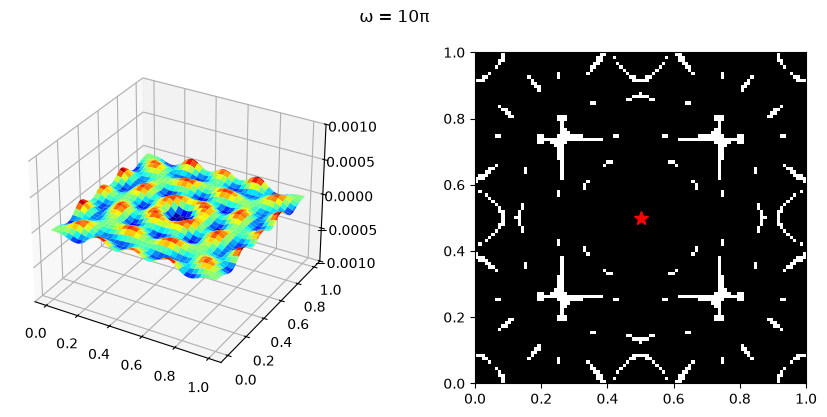

In [7]:
U = run("ω = 10π", 10 * pi)

час: 0.4 с


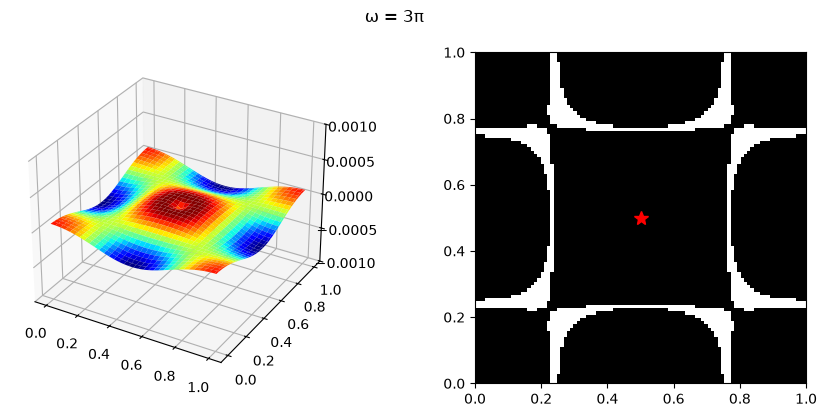

In [8]:
U = run("ω = 3π", 3 * pi)

час: 0.5 с


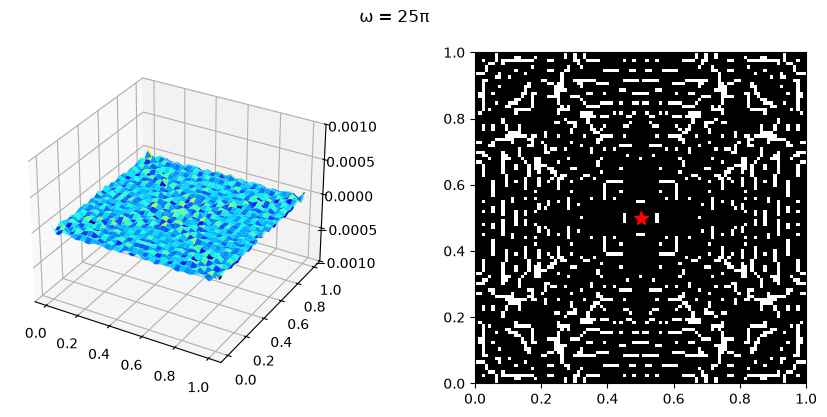

In [9]:
U = run("ω = 25π", 25 * pi)

### 4.2. Два генератори

час: 0.4 с


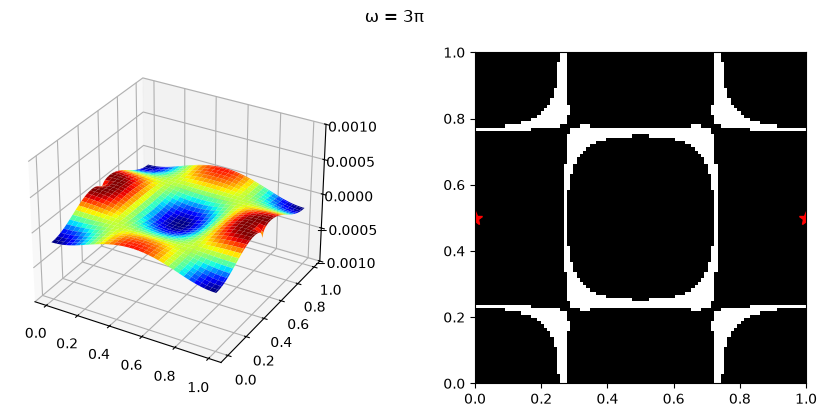

In [10]:
two = ((0, 0.5, 0), (1, 0.5, 0))
U = run("ω = 3π", 3 * pi, sources=two)

час: 0.5 с


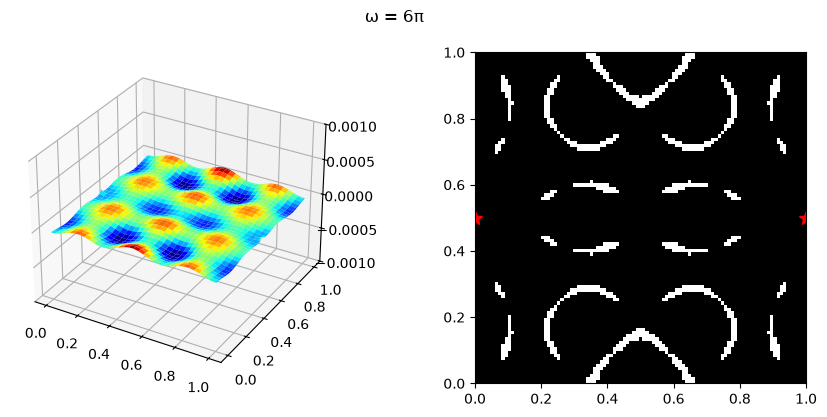

In [11]:
U = run("ω = 6π", 6 * pi, sources=two)

### 4.3. Закріплені краї

час: 0.5 с


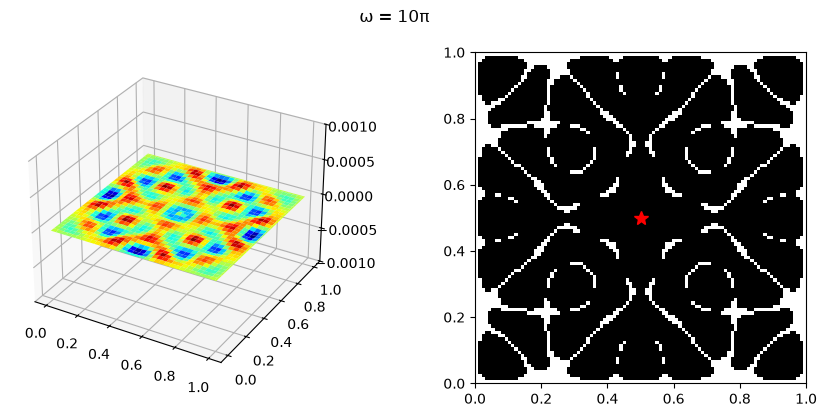

In [12]:
U = run("ω = 10π", 10 * pi, fixed="lrbt")

час: 0.5 с


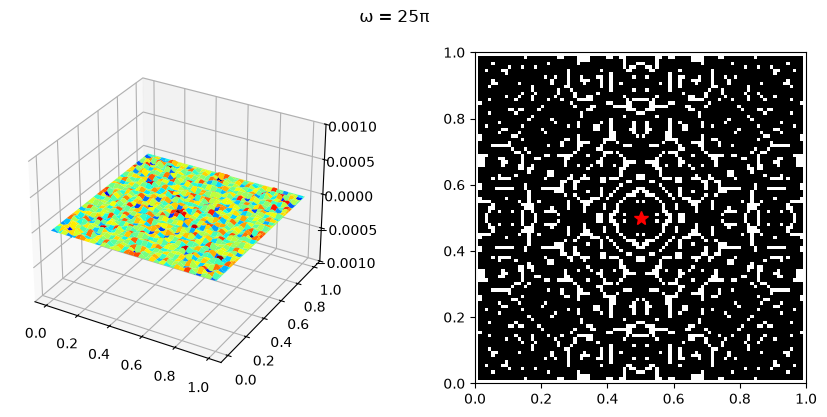

In [13]:
U = run("ω = 25π", 25 * pi, fixed="lrbt")

### Порівняння схем

розійшлась на t = 0.14
час: 0.2 с
час: 0.4 с
час: 0.5 с


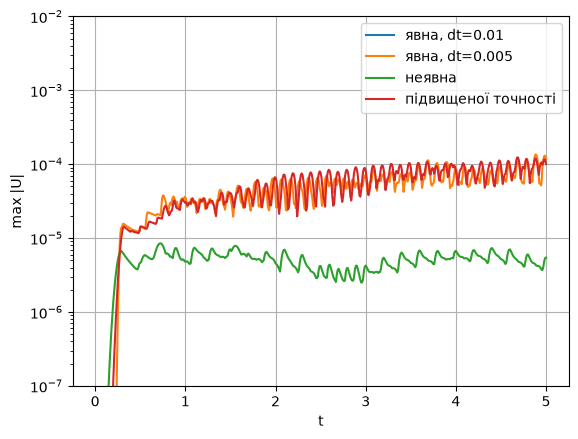

In [14]:
tests = {
    "явна, dt=0.01":         dict(scheme="explicit"),
    "явна, dt=0.005":        dict(scheme="explicit", dt=0.005, steps=1000),
    "неявна":                dict(scheme="implicit"),
    "підвищеної точності":   dict(scheme="cn"),
}

for name, kw in tests.items():
    U, t = solve(**kw)
    plt.plot(t, np.abs(U[:, :33, :33]).max(axis=(1, 2)), label=name)
plt.yscale("log")
plt.ylim(1e-7, 1e-2)
plt.xlabel("t")
plt.ylabel("max |U|")
plt.legend()
plt.grid()
plt.show()

час: 0.5 с


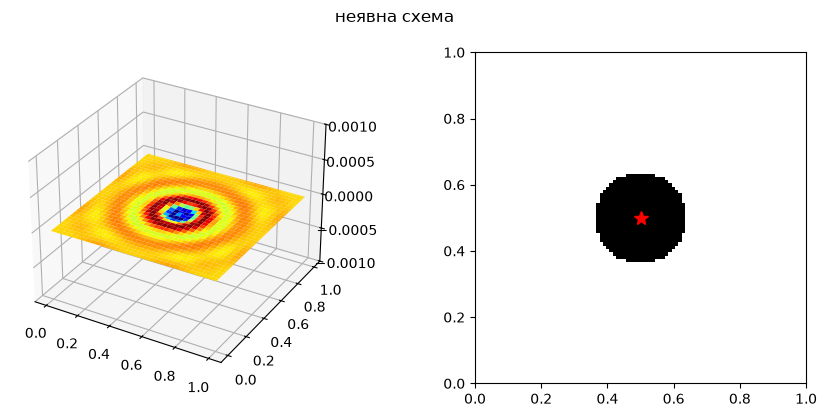

час: 0.2 с


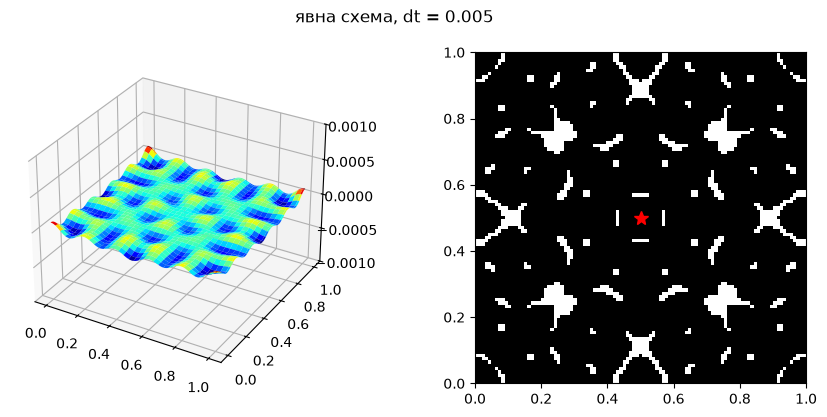

час: 0.4 с


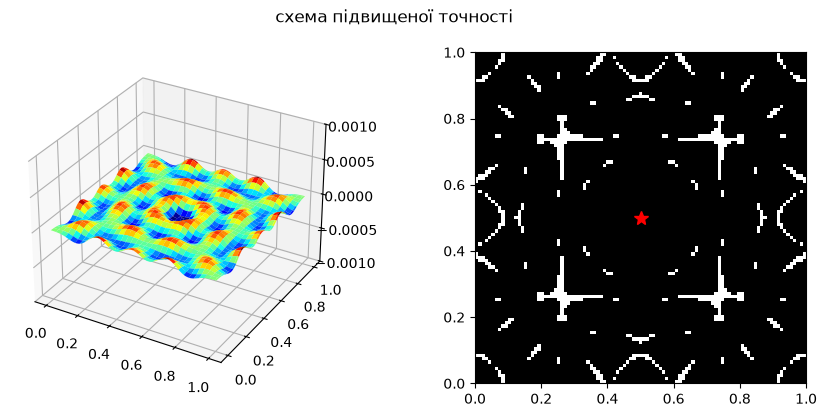

In [15]:
U, t = solve(scheme="implicit")
show(U, 10 * pi, "неявна схема")
U, t = solve(scheme="explicit", dt=0.005, steps=1000)
show(U, 10 * pi, "явна схема, dt = 0.005", dt=0.005)
U, t = solve(scheme="cn")
show(U, 10 * pi, "схема підвищеної точності")

### Модифікації

#### Чотири генератори

час: 0.4 с


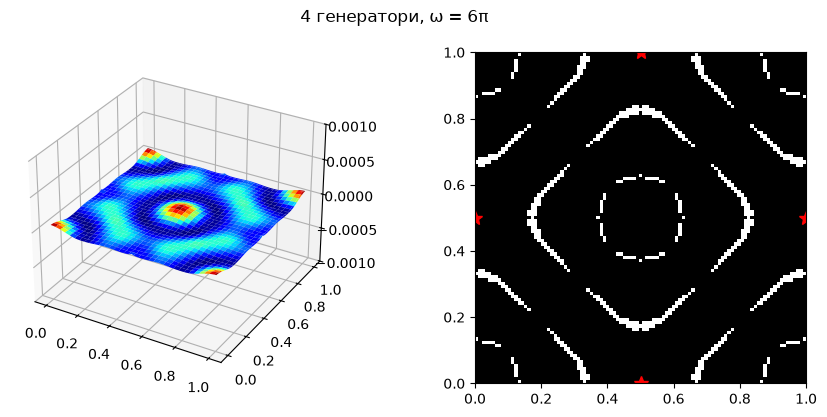

In [16]:
four = ((0, 0.5, 0), (1, 0.5, 0), (0.5, 0, 0), (0.5, 1, 0))
U = run("4 генератори, ω = 6π", 6 * pi, sources=four)

#### Генератор не в центрі

час: 0.4 с


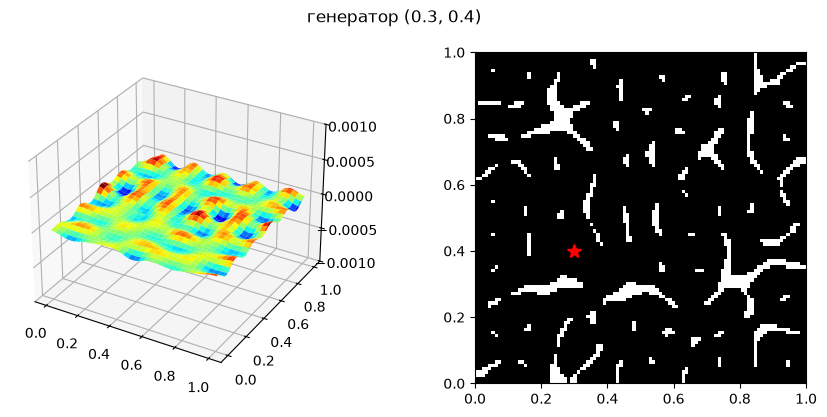

In [17]:
U = run("генератор (0.3, 0.4)", 10 * pi, sources=((0.3, 0.4, 0),))

#### Змішані граничні умови

час: 0.4 с


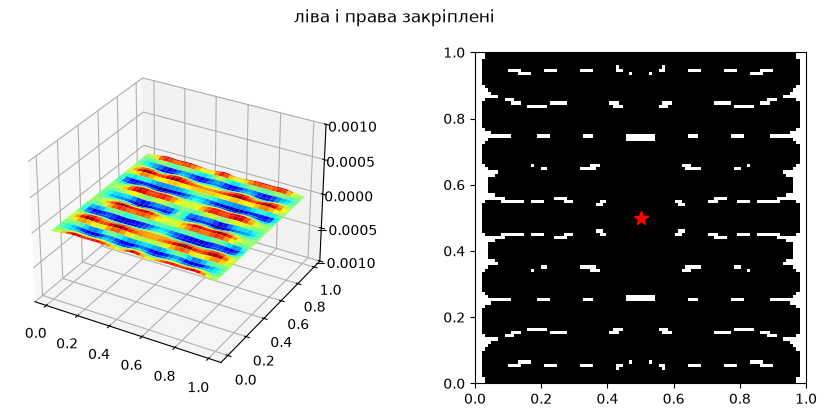

In [18]:
U = run("ліва і права закріплені", 10 * pi, fixed="lr")

#### Прямокутна мембрана 1.5 × 1

час: 0.6 с


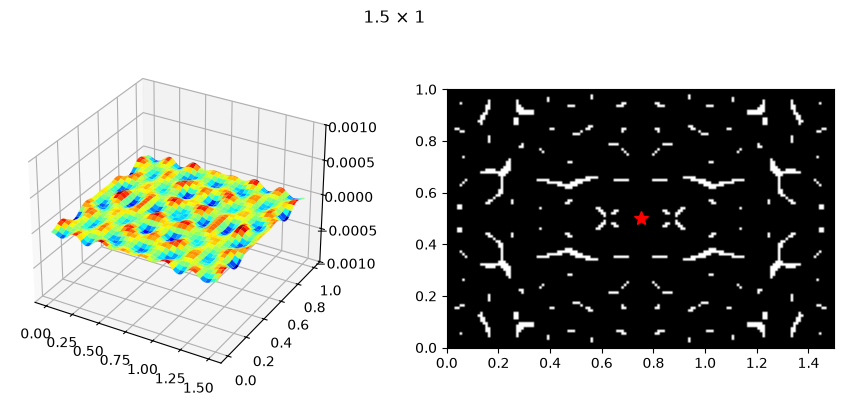

In [19]:
U = run("1.5 × 1", 10 * pi, nx=151, sources=((0.75, 0.5, 0),))

#### Генератори в протифазі

час: 0.4 с


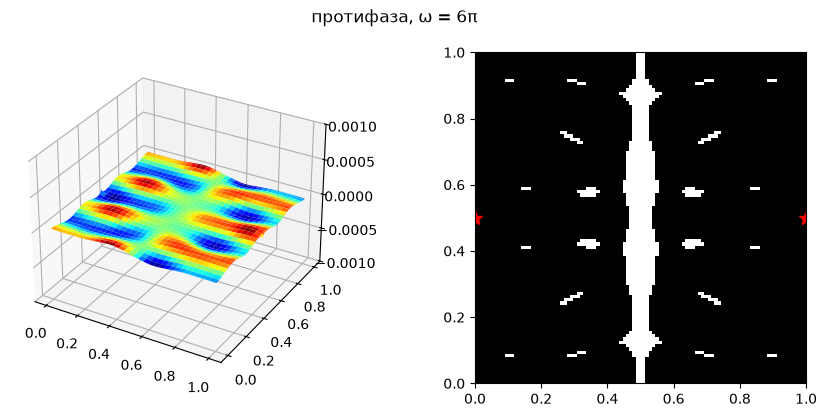

In [20]:
U = run("протифаза, ω = 6π", 6 * pi, sources=((0, 0.5, 0), (1, 0.5, pi)))

#### Затухання

час: 0.9 с


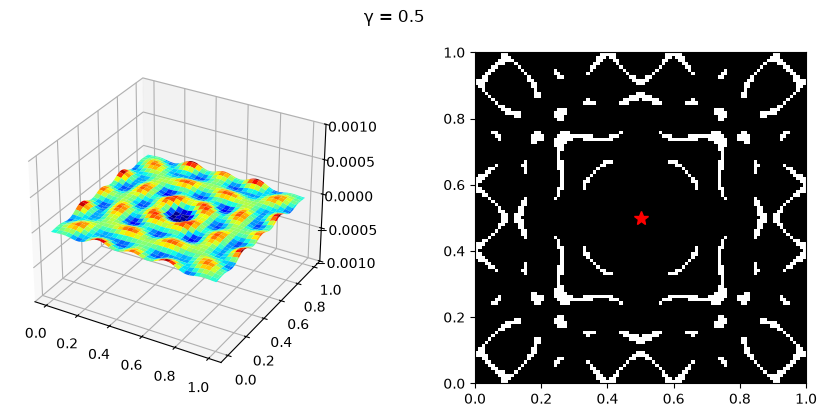

In [21]:
U = run("γ = 0.5", 10 * pi, gamma=0.5, steps=1000)

### Власні частоти

In [22]:
def modes(w, kind="free", tol=0.1):
    r = range(0, 40) if kind == "free" else range(1, 40)
    out = []
    for m in r:
        for n in r:
            wmn = pi * np.hypot(m, n)
            if m <= n and abs(wmn - w) < tol * pi:
                out.append((m, n, round(float(wmn / pi), 2)))
    return out


for kind, w in [("free", 3), ("free", 10), ("free", 25), ("fixed", 10), ("fixed", 25)]:
    print(kind, w, modes(w * pi, kind))

free 3 [(0, 3, 3.0)]
free 10 [(0, 10, 10.0), (1, 10, 10.05), (6, 8, 10.0)]
free 25 [(0, 25, 25.0), (1, 25, 25.02), (2, 25, 25.08), (7, 24, 25.0), (10, 23, 25.08), (12, 22, 25.06), (15, 20, 25.0)]
fixed 10 [(1, 10, 10.05), (6, 8, 10.0)]
fixed 25 [(1, 25, 25.02), (2, 25, 25.08), (7, 24, 25.0), (10, 23, 25.08), (12, 22, 25.06), (15, 20, 25.0)]


### Висновки
1. Явна схема при dt = h = 0.01 нестійка, при dt = 0.005 працює.
2. Звичайна неявна схема стійка, але гасить коливання.
3. Фігура залежить від частоти, граничних умов і розташування генераторів.